# Model Weights Explorer

A hands-on notebook for understanding what neural network weights actually look like — their shapes, distributions, and structure — using GPT-2 (124M params) as a concrete example.

> **Why not gpt-oss-120b?** A 120B parameter model weighs ~240GB in fp16. You'd need a multi-GPU server just to load it. GPT-2 has the *exact same architecture* (decoder-only transformer) at a scale you can inspect locally in seconds.

## 1. Select the Project Kernel

All dependencies are pre-installed in this project's shared uv environment — **no manual `pip install` needed**.

**In VS Code:**
1. Open the Command Palette (`⇧⌘P`) → `Notebook: Select Kernel`
2. Choose **Python Environments…** → pick the interpreter at `src/exercises/.venv`

If the venv doesn't exist yet, run once from the repo root:
```bash
cd src/exercises && uv sync
```
Then reload VS Code and select the kernel above.

The cell below confirms you're using the right Python.

In [ ]:
import sys

# Should print: .../cloud-native-geo-tutorial/src/exercises/.venv/bin/python
# If it shows a different path, follow the kernel selection steps above.
print("Kernel Python:", sys.executable)

In [3]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from transformers import AutoModelForCausalLM, AutoTokenizer

print(f"torch     : {torch.__version__}")
print(f"transformers installed ✓")

torch     : 2.10.0
transformers installed ✓


## 2. Load GPT-2 (124M Parameters)

GPT-2 is a decoder-only transformer — the same architecture family as GPT-3, GPT-4, and gpt-oss-120b, just smaller. It downloads ~500MB from Hugging Face Hub (cached after first run).

In [4]:
MODEL_NAME = "gpt2"  # 124M params, ~500MB download, no access restrictions

print(f"Loading {MODEL_NAME} ...")
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME)
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Put in eval mode — no dropout, no gradient tracking needed for inspection
model.eval()

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nTotal parameters    : {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Approximate size    : {total_params * 4 / 1e6:.1f} MB (fp32)")

Loading gpt2 ...


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]


Total parameters    : 124,439,808
Trainable parameters: 124,439,808
Approximate size    : 497.8 MB (fp32)


## 3. Inspect Architecture and Weight Shapes

Every "weight" is just a **tensor** — a multi-dimensional array of floating point numbers. The *shape* tells you what the layer does:
- `(vocab_size, embed_dim)` → embedding lookup table, one row per token
- `(3 * embed_dim, embed_dim)` → combined Q/K/V projection (3-in-1)
- `(4 * embed_dim, embed_dim)` → MLP expansion (typical transformer uses 4x intermediate size)

In [5]:
print("=" * 70)
print(f"{'Layer name':<55} {'Shape':<20} {'Params':>10}")
print("=" * 70)

for name, param in model.named_parameters():
    shape_str = str(list(param.shape))
    print(f"{name:<55} {shape_str:<20} {param.numel():>10,}")

print("=" * 70)
print(f"{'TOTAL':<55} {'':20} {total_params:>10,}")

Layer name                                              Shape                    Params
transformer.wte.weight                                  [50257, 768]         38,597,376
transformer.wpe.weight                                  [1024, 768]             786,432
transformer.h.0.ln_1.weight                             [768]                       768
transformer.h.0.ln_1.bias                               [768]                       768
transformer.h.0.attn.c_attn.weight                      [768, 2304]           1,769,472
transformer.h.0.attn.c_attn.bias                        [2304]                    2,304
transformer.h.0.attn.c_proj.weight                      [768, 768]              589,824
transformer.h.0.attn.c_proj.bias                        [768]                       768
transformer.h.0.ln_2.weight                             [768]                       768
transformer.h.0.ln_2.bias                               [768]                       768
transformer.h.0.mlp.c_fc.weight 

## 4. Extract Raw Tensors and Compute Statistics

`state_dict()` gives you a plain dictionary of `{name: tensor}` — the actual numbers that define the model. Converting to numpy lets you use familiar statistical tools.

In [6]:
state = model.state_dict()

# Layers we want to inspect closely
layers_of_interest = [
    "transformer.wte.weight",               # Token embedding table  (50257, 768)
    "transformer.h.0.attn.c_attn.weight",   # Block 0 — Q/K/V proj   (768, 2304)
    "transformer.h.0.mlp.c_fc.weight",      # Block 0 — MLP expand   (768, 3072)
    "transformer.h.11.attn.c_attn.weight",  # Block 11 (last) — attn
    "transformer.h.11.mlp.c_fc.weight",     # Block 11 — MLP
    "transformer.ln_f.weight",              # Final layer norm scale  (768,)
]

print(f"{'Layer':<45} {'Shape':<16} {'Min':>8} {'Max':>8} {'Mean':>8} {'Std':>8}")
print("-" * 100)

tensors = {}
for name in layers_of_interest:
    t = state[name].float().numpy()
    tensors[name] = t
    print(f"{name:<45} {str(list(t.shape)):<16} {t.min():>8.4f} {t.max():>8.4f} {t.mean():>8.4f} {t.std():>8.4f}")

Layer                                         Shape                 Min      Max     Mean      Std
----------------------------------------------------------------------------------------------------
transformer.wte.weight                        [50257, 768]      -1.2698   1.7852   0.0004   0.1437
transformer.h.0.attn.c_attn.weight            [768, 2304]       -2.8436   2.7956   0.0001   0.1996
transformer.h.0.mlp.c_fc.weight               [768, 3072]       -2.3131   4.5877  -0.0007   0.1412
transformer.h.11.attn.c_attn.weight           [768, 2304]       -2.2638   2.3071   0.0001   0.1285
transformer.h.11.mlp.c_fc.weight              [768, 3072]       -1.9649   1.6926  -0.0018   0.1300
transformer.ln_f.weight                       [768]              0.0044  17.4193   1.5078   1.3902


## 5. Weight Distributions — Histograms

A key fact about trained neural networks: **weights cluster tightly around zero** following a roughly Gaussian distribution. This is intentional — large weights cause instability, and regularization keeps them small. Notice how the embedding table (which has to distinguish 50,257 tokens) has a slightly wider spread than internal projection layers.

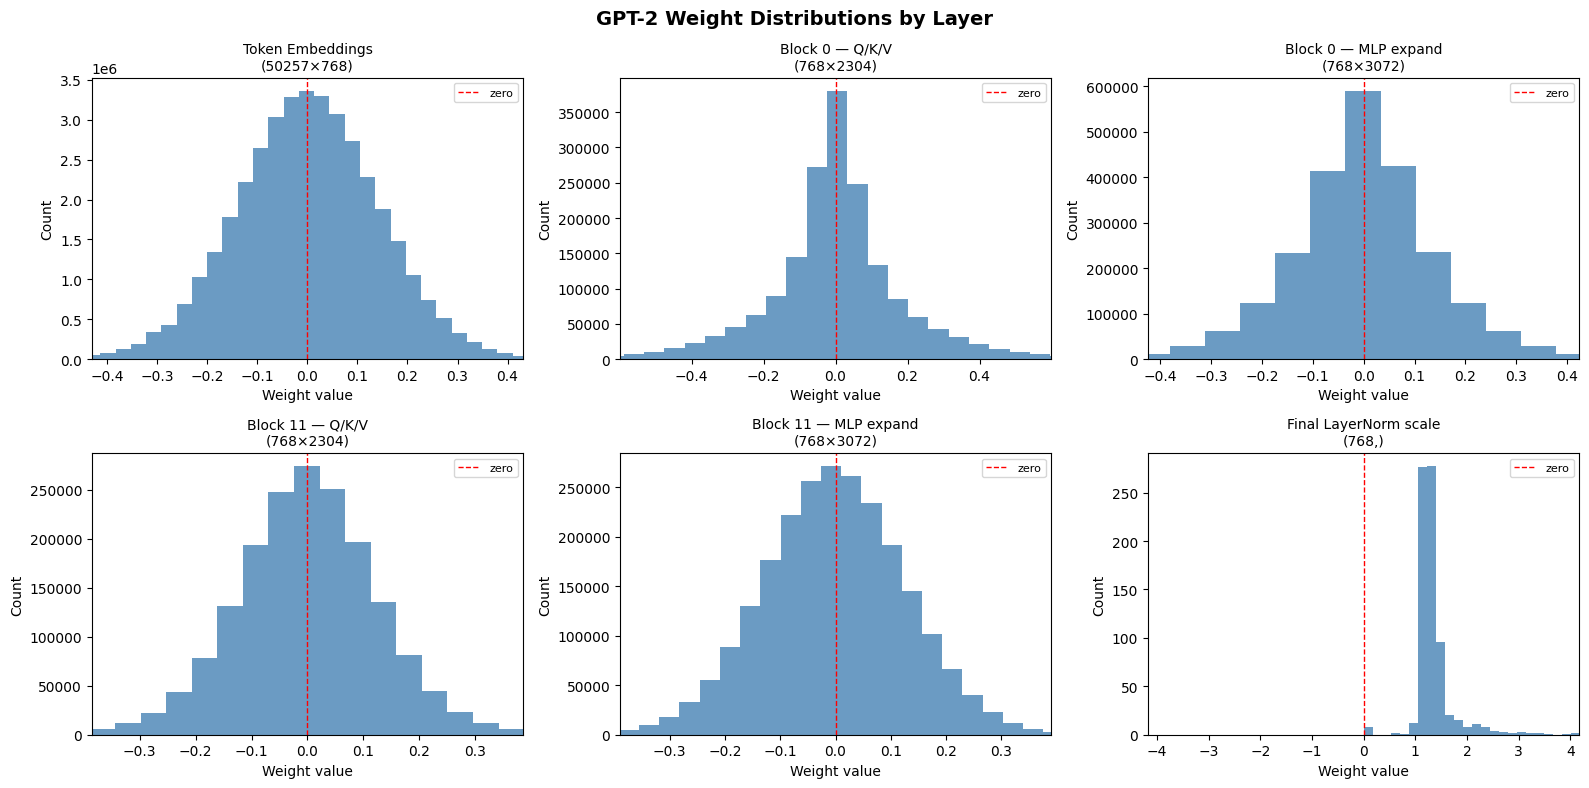

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

short_names = [
    "Token Embeddings\n(50257×768)",
    "Block 0 — Q/K/V\n(768×2304)",
    "Block 0 — MLP expand\n(768×3072)",
    "Block 11 — Q/K/V\n(768×2304)",
    "Block 11 — MLP expand\n(768×3072)",
    "Final LayerNorm scale\n(768,)",
]

for ax, (name, short) in zip(axes, zip(layers_of_interest, short_names)):
    data = tensors[name].flatten()
    ax.hist(data, bins=100, color="steelblue", alpha=0.8, edgecolor="none")
    ax.axvline(0, color="red", linewidth=1, linestyle="--", label="zero")
    ax.set_title(short, fontsize=10)
    ax.set_xlabel("Weight value")
    ax.set_ylabel("Count")
    ax.legend(fontsize=8)
    # Clip x-axis to ±3σ so outliers don't squash the shape
    std = data.std()
    ax.set_xlim(-3 * std, 3 * std)

fig.suptitle("GPT-2 Weight Distributions by Layer", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## 6. Weight Matrices as Heatmaps

Rendering a weight matrix as an image makes structure visible. A diverging colormap centered at zero (blue = negative, white = zero, red = positive) reveals learned patterns. We sample a small slice so it renders quickly — GPT-2's full Q/K/V matrix is 768×2304.

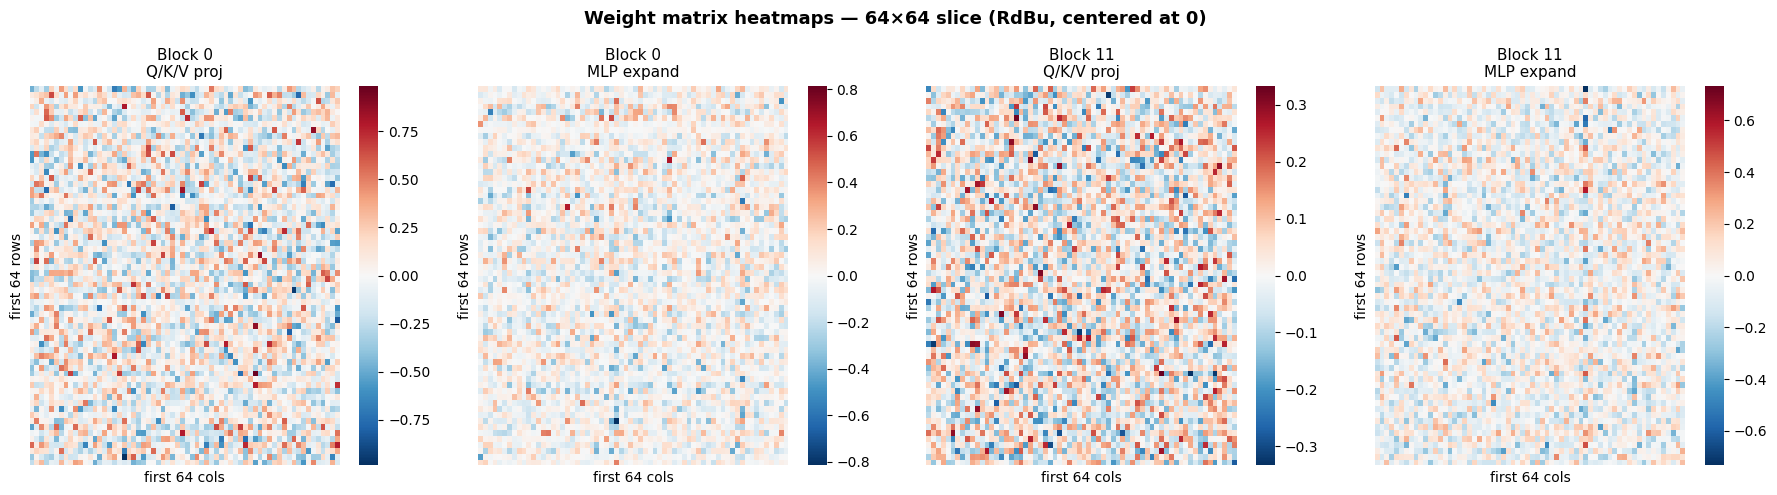

In [8]:
SLICE = 64  # render a 64×64 slice of each matrix

heatmap_layers = {
    "Block 0\nQ/K/V proj": tensors["transformer.h.0.attn.c_attn.weight"][:SLICE, :SLICE],
    "Block 0\nMLP expand": tensors["transformer.h.0.mlp.c_fc.weight"][:SLICE, :SLICE],
    "Block 11\nQ/K/V proj": tensors["transformer.h.11.attn.c_attn.weight"][:SLICE, :SLICE],
    "Block 11\nMLP expand": tensors["transformer.h.11.mlp.c_fc.weight"][:SLICE, :SLICE],
}

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

for ax, (title, matrix) in zip(axes, heatmap_layers.items()):
    vmax = np.abs(matrix).max()
    sns.heatmap(
        matrix,
        ax=ax,
        cmap="RdBu_r",
        center=0,
        vmin=-vmax,
        vmax=vmax,
        xticklabels=False,
        yticklabels=False,
        cbar=True,
    )
    ax.set_title(title, fontsize=11)
    ax.set_xlabel(f"first {SLICE} cols")
    ax.set_ylabel(f"first {SLICE} rows")

fig.suptitle(f"Weight matrix heatmaps — {SLICE}×{SLICE} slice (RdBu, centered at 0)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

## 7. Weight Magnitude Across All Layers

Does weight magnitude change as you go deeper into the network? Plot mean absolute value and standard deviation for every weight matrix across all 12 transformer blocks. This can reveal whether the model has gradient-related issues (exploding/vanishing weights) or is well-trained.

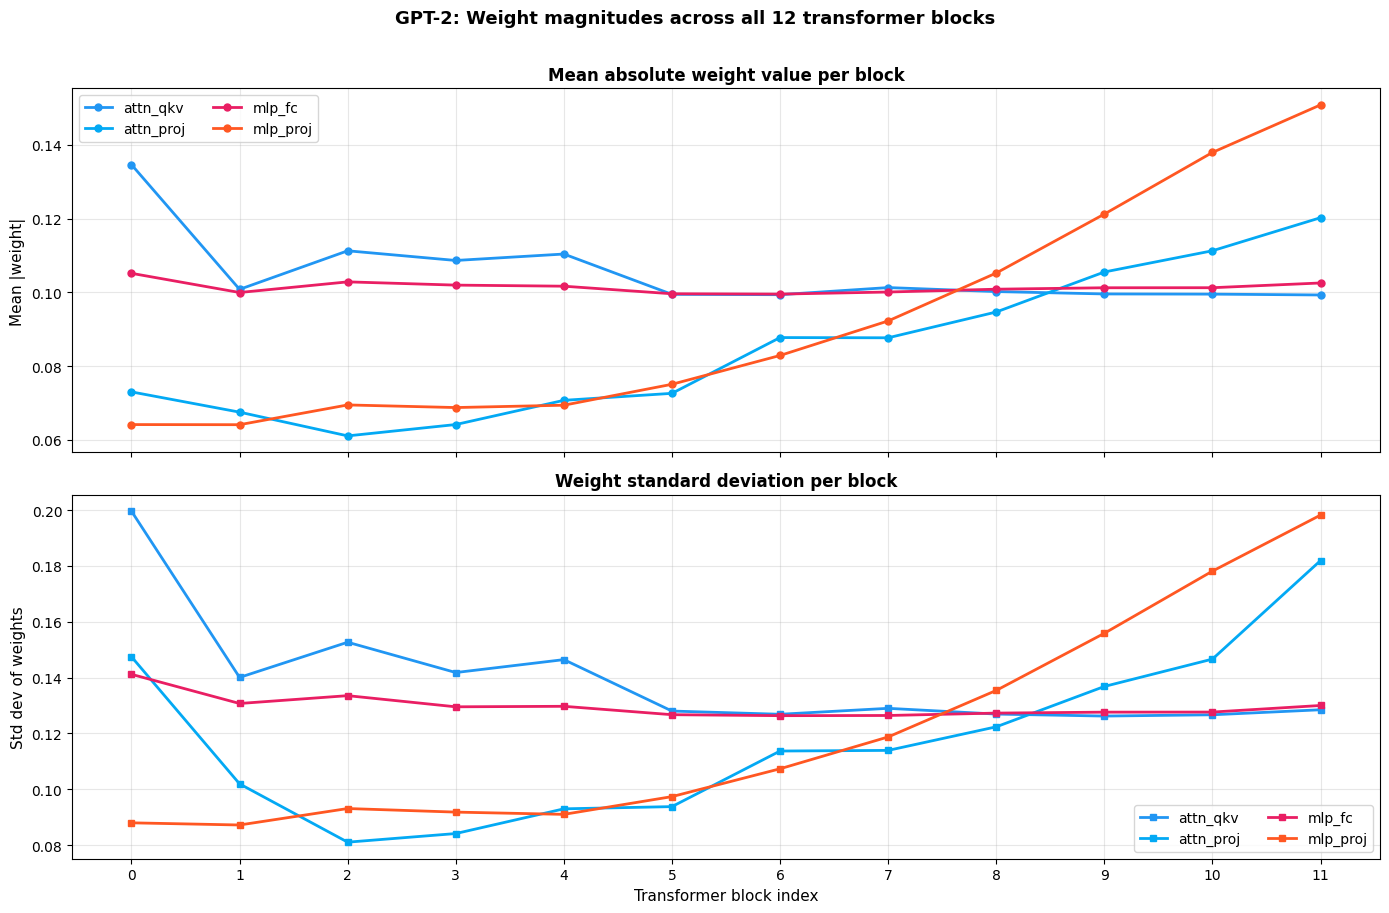


Key observations:
- Weights stay in a consistent, narrow range across all blocks → well-trained, no gradient explosion
- MLP layers (pink/orange) typically have higher std than attention layers — they act as memory banks
- A 120B model has the same *structure*, just 120× more parameters and many more blocks


In [9]:
layer_types = {
    "attn_qkv":  "attn.c_attn.weight",
    "attn_proj": "attn.c_proj.weight",
    "mlp_fc":    "mlp.c_fc.weight",
    "mlp_proj":  "mlp.c_proj.weight",
}

n_layers = model.config.n_layer  # 12 for gpt2
layer_indices = list(range(n_layers))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

colors = {"attn_qkv": "#2196F3", "attn_proj": "#03A9F4", "mlp_fc": "#E91E63", "mlp_proj": "#FF5722"}

for ltype, suffix in layer_types.items():
    means, stds = [], []
    for i in layer_indices:
        key = f"transformer.h.{i}.{suffix}"
        t = state[key].float().numpy()
        means.append(np.abs(t).mean())
        stds.append(t.std())
    ax1.plot(layer_indices, means, marker="o", label=ltype, color=colors[ltype], linewidth=2, markersize=5)
    ax2.plot(layer_indices, stds,  marker="s", label=ltype, color=colors[ltype], linewidth=2, markersize=5)

ax1.set_ylabel("Mean |weight|", fontsize=11)
ax1.set_title("Mean absolute weight value per block", fontsize=12, fontweight="bold")
ax1.legend(ncol=2)
ax1.grid(True, alpha=0.3)

ax2.set_ylabel("Std dev of weights", fontsize=11)
ax2.set_xlabel("Transformer block index", fontsize=11)
ax2.set_title("Weight standard deviation per block", fontsize=12, fontweight="bold")
ax2.legend(ncol=2)
ax2.grid(True, alpha=0.3)
ax2.set_xticks(layer_indices)

fig.suptitle("GPT-2: Weight magnitudes across all 12 transformer blocks", fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

print("\nKey observations:")
print("- Weights stay in a consistent, narrow range across all blocks → well-trained, no gradient explosion")
print("- MLP layers (pink/orange) typically have higher std than attention layers — they act as memory banks")
print("- A 120B model has the same *structure*, just 120× more parameters and many more blocks")